In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option('display.width', 120)
plt.rcParams['figure.figsize'] = (8, 5)

**Q1.** Load the file. Report shape, dtypes, and missing counts per column.

In [6]:
df = pd.read_csv('/content/suvidha_loan_predictions_raw - suvidha_loan_predictions_raw.csv.csv')
print("Shape:", df.shape)
print(df.dtypes)
print("\nMissing counts:")
print(df.isna().sum())

Shape: (2400, 9)
loan_id            object
loan_amount        object
tenure_months       int64
interest_rate     float64
borrower_age       object
monthly_income     object
actual_default     object
model_flag         object
risk_score        float64
dtype: object

Missing counts:
loan_id            0
loan_amount        0
tenure_months      0
interest_rate      0
borrower_age      38
monthly_income    36
actual_default    40
model_flag        22
risk_score         0
dtype: int64


**Q2.** Clean loan_amount to numeric (strip currency text and commas).

In [7]:
def clean_amount(v):
    s = str(v).strip().replace('Rs', '').replace(',', '').strip()
    try:
        return float(s)
    except ValueError:
        return np.nan

n_text = df['loan_amount'].astype(str).str.contains('Rs').sum()
df['loan_amount'] = df['loan_amount'].apply(clean_amount)
print(f"Rows with 'Rs'-prefixed text: {n_text}")
print("loan_amount missing after cleaning:", df['loan_amount'].isna().sum())
print(df['loan_amount'].describe())

Rows with 'Rs'-prefixed text: 469
loan_amount missing after cleaning: 0
count      2400.000000
mean      92862.462195
std       39819.158429
min       22062.878150
25%       63410.589692
50%       86127.625580
75%      114590.619250
max      287236.577800
Name: loan_amount, dtype: float64


**Q3.** Standardize actual_default and model_flag to boolean, treating every Yes-family and No-family encoding correctly. Show the distinct raw values you mapped.

In [8]:
print("Raw actual_default values:", df['actual_default'].unique())
print("Raw model_flag values:", df['model_flag'].unique())

YES = {'yes', 'y', '1', 'true'}
NO = {'no', 'n', '0', 'false'}

def to_bool(v):
    if pd.isna(v):
        return np.nan
    s = str(v).strip().lower()
    if s in YES:
        return True
    if s in NO:
        return False
    return np.nan

df['actual_default'] = df['actual_default'].apply(to_bool)
df['model_flag'] = df['model_flag'].apply(to_bool)
print("\nactual_default after mapping:", df['actual_default'].value_counts(dropna=False).to_dict())
print("model_flag after mapping:", df['model_flag'].value_counts(dropna=False).to_dict())

Raw actual_default values: ['FALSE' 'No' '0' 'N' '1' 'Yes' nan 'TRUE' 'Y']
Raw model_flag values: ['No' 'FALSE' 'N' 'Yes' 'Y' 'TRUE' '0' nan '1']

actual_default after mapping: {False: 2161, True: 199, nan: 40}
model_flag after mapping: {False: 2222, True: 156, nan: 22}


**Q4.** Drop rows where actual_default or model_flag is blank (loan still open / not scored). Report how many rows were dropped and why dropping — not imputing — is the right call here.

In [9]:
before_n = len(df)
df = df.dropna(subset=['actual_default', 'model_flag']).copy()
after_n = len(df)
print(f"Rows dropped: {before_n - after_n}  (before={before_n}, after={after_n})")

Rows dropped: 61  (before=2400, after=2339)


**Q5.** Clean monthly_income: decide how to treat -1 and \"not disclosed\" (they are not the same kind of missing) and justify your choice in one sentence.

In [10]:
def clean_income(v):
    if pd.isna(v):
        return np.nan
    s = str(v).strip().lower()
    if s == 'not disclosed':
        return np.nan
    try:
        f = float(s)
        return np.nan if f == -1 else f
    except ValueError:
        return np.nan

n_not_disclosed = df['monthly_income'].astype(str).str.lower().eq('not disclosed').sum()
n_neg_one = pd.to_numeric(df['monthly_income'], errors='coerce').eq(-1).sum()
df['monthly_income'] = df['monthly_income'].apply(clean_income)
print(f"'not disclosed' rows: {n_not_disclosed}   '-1' sentinel rows: {n_neg_one}")
print("monthly_income missing after cleaning:", df['monthly_income'].isna().sum())

df.to_csv('suvidha_loan_predictions_clean.csv', index=False)
print("\nSaved cleaned file: suvidha_loan_predictions_clean.csv  |  final row count:", len(df))

'not disclosed' rows: 29   '-1' sentinel rows: 28
monthly_income missing after cleaning: 91

Saved cleaned file: suvidha_loan_predictions_clean.csv  |  final row count: 2339


**Q6.** Build the confusion matrix (actual_default vs model_flag) as a 2×2 table. Label which cell is TP, FP, TN, FN in a business sentence each.

In [11]:
TP = ((df['actual_default'] == True) & (df['model_flag'] == True)).sum()
FP = ((df['actual_default'] == False) & (df['model_flag'] == True)).sum()
TN = ((df['actual_default'] == False) & (df['model_flag'] == False)).sum()
FN = ((df['actual_default'] == True) & (df['model_flag'] == False)).sum()

cm = pd.DataFrame([[TP, FN], [FP, TN]],
                   index=['Actual: Default', 'Actual: No Default'],
                   columns=['Predicted: Default', 'Predicted: No Default'])
print(cm)
print(f"\nTP={TP}  FP={FP}  TN={TN}  FN={FN}")

                    Predicted: Default  Predicted: No Default
Actual: Default                    133                     64
Actual: No Default                  20                   2122

TP=133  FP=20  TN=2122  FN=64


**Q7.** Compute accuracy. Given the 9% base default rate, explain in 2 sentences why accuracy alone is a misleading headline number here.

In [12]:
accuracy = (TP + TN) / (TP + FP + TN + FN)
base_rate = df['actual_default'].mean()
print(f"Accuracy: {accuracy:.4f}")
print(f"Base default rate: {base_rate:.4f}")
print(f"Accuracy of an always-predict-'No default' model: {1 - base_rate:.4f}")

Accuracy: 0.9641
Base default rate: 0.0842
Accuracy of an always-predict-'No default' model: 0.9158


**Q8.** Compute precision for the \"predicted default\" class. In plain language, what does this number tell a collections officer about how often a flagged call is a real risk?

In [13]:
precision = TP / (TP + FP)
print(f"Precision: {precision:.4f}")

Precision: 0.8693


**Q9.** Compute recall (sensitivity) for the \"predicted default\" class. What does this tell the risk team about defaults the model is missing?

In [14]:
recall = TP / (TP + FN)
print(f"Recall: {recall:.4f}")

Recall: 0.6751


**Q10.** Compute specificity. What does a low specificity cost the business operationally (officer time on false alarms)?

In [15]:
specificity = TN / (TN + FP)
print(f"Specificity: {specificity:.4f}")

Specificity: 0.9907


**Q11.** Compute F1-score. Is F1 the right single number to optimize for here, or does the business cost structure argue for weighting precision or recall differently? Justify.

In [16]:
f1 = 2 * precision * recall / (precision + recall)
print(f"F1-score: {f1:.4f}")

F1-score: 0.7600


**Q12.** Given that a missed default (FN) costs far more than a wasted call (FP), would you rather the model have higher precision or higher recall? Explain using the actual FN and FP counts from Q6.

**Higher recall.** The pilot already has very few false alarms (FP=20) relative to true negatives (2,122) — false alarms are cheap and rare — but it still misses 64 real defaults (FN), each of which is a borrower who defaults with no early warning at all. Since a missed default costs far more than an officer making an unnecessary call, it's worth trading some precision away (accepting more FPs) to push recall up and catch more of those 64 currently-missed defaults.

**Q13.** Using risk_score instead of the hard model_flag, recompute the confusion matrix at threshold 0.3 instead of the model's default cutoff. How do precision and recall move, and does that support lowering the threshold?

In [17]:
pred_03 = df['risk_score'] >= 0.3

TP2 = ((df['actual_default'] == True) & (pred_03 == True)).sum()
FP2 = ((df['actual_default'] == False) & (pred_03 == True)).sum()
TN2 = ((df['actual_default'] == False) & (pred_03 == False)).sum()
FN2 = ((df['actual_default'] == True) & (pred_03 == False)).sum()
prec2 = TP2 / (TP2 + FP2)
rec2 = TP2 / (TP2 + FN2)

print(pd.DataFrame([[TP2, FN2], [FP2, TN2]],
                    index=['Actual: Default', 'Actual: No Default'],
                    columns=['Predicted: Default', 'Predicted: No Default']))
print(f"\nAt threshold 0.3 -> precision={prec2:.4f}, recall={rec2:.4f}")
print(f"vs original model_flag  -> precision={precision:.4f}, recall={recall:.4f}")

                    Predicted: Default  Predicted: No Default
Actual: Default                    197                      0
Actual: No Default                1478                    664

At threshold 0.3 -> precision=0.1176, recall=1.0000
vs original model_flag  -> precision=0.8693, recall=0.6751


**Q14.** Plot precision and recall against threshold (0.1 to 0.9, steps of 0.1) using risk_score. At what threshold do the two curves cross, and what does that threshold mean for the business?

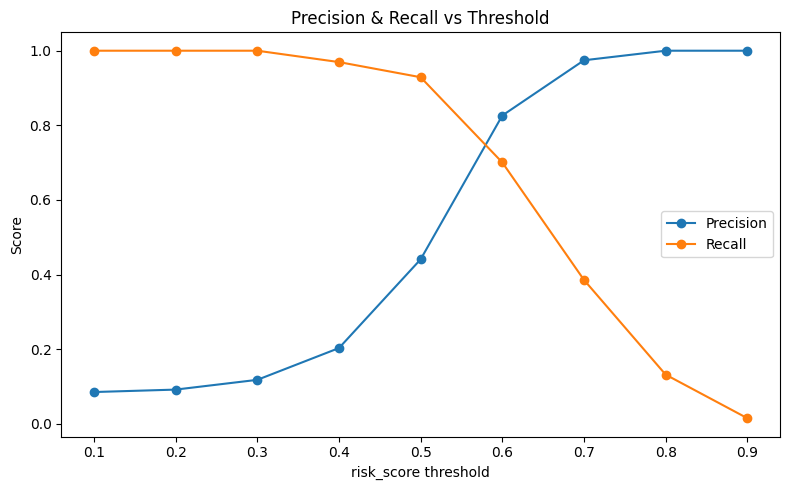

    threshold  precision    recall  prec_minus_rec
0        0.50   0.440964  0.928934       -0.487970
1        0.51   0.471354  0.918782       -0.447428
2        0.52   0.517341  0.908629       -0.391288
3        0.53   0.553797  0.888325       -0.334527
4        0.54   0.592199  0.847716       -0.255517
5        0.55   0.631783  0.827411       -0.195628
6        0.56   0.672340  0.802030       -0.129690
7        0.57   0.724299  0.786802       -0.062503
8        0.58   0.758794  0.766497       -0.007703
9        0.59   0.807910  0.725888        0.082021
10       0.60   0.825301  0.695431        0.129870
11       0.61   0.856250  0.695431        0.160819


In [18]:
thresholds = np.arange(0.1, 0.95, 0.1)
precisions, recalls = [], []
for t in thresholds:
    pred = df['risk_score'] >= t
    tp = ((df['actual_default'] == True) & (pred == True)).sum()
    fp = ((df['actual_default'] == False) & (pred == True)).sum()
    fn = ((df['actual_default'] == True) & (pred == False)).sum()
    precisions.append(tp / (tp + fp) if (tp + fp) > 0 else np.nan)
    recalls.append(tp / (tp + fn) if (tp + fn) > 0 else np.nan)

fig, ax = plt.subplots()
ax.plot(thresholds, precisions, marker='o', label='Precision')
ax.plot(thresholds, recalls, marker='o', label='Recall')
ax.set_xlabel('risk_score threshold'); ax.set_ylabel('Score')
ax.set_title('Precision & Recall vs Threshold')
ax.legend()
plt.tight_layout()
plt.savefig('precision_recall_vs_threshold.png', dpi=100)
plt.show()

# finer sweep to pinpoint the exact crossing point
fine_t = np.arange(0.50, 0.62, 0.01)
fine_diff = []
for t in fine_t:
    pred = df['risk_score'] >= t
    tp = ((df['actual_default'] == True) & (pred == True)).sum()
    fp = ((df['actual_default'] == False) & (pred == True)).sum()
    fn = ((df['actual_default'] == True) & (pred == False)).sum()
    p = tp / (tp + fp) if (tp + fp) > 0 else np.nan
    r = tp / (tp + fn) if (tp + fn) > 0 else np.nan
    fine_diff.append((t, p, r, p - r))
cross_df = pd.DataFrame(fine_diff, columns=['threshold', 'precision', 'recall', 'prec_minus_rec'])
print(cross_df)

**Q15.** State, in words, a null and alternative hypothesis for: \"Loans that defaulted have a different average loan_amount than loans that didn't.\"

**H0 (null):** The average loan amount is the same for loans that defaulted and loans that didn't default (the difference in population means is zero).
**H1 (alternative):** The average loan amount differs between loans that defaulted and loans that didn't (a two-sided test — we're not assuming which group is higher going in).

**Q16.** Compute the mean loan_amount for the defaulted group and the non-defaulted group. Is there an apparent difference?

In [19]:
grp_default = df.loc[df['actual_default'] == True, 'loan_amount'].dropna()
grp_no_default = df.loc[df['actual_default'] == False, 'loan_amount'].dropna()

print(f"Defaulted group    : n={len(grp_default)}, mean=Rs {grp_default.mean():,.2f}")
print(f"Non-defaulted group: n={len(grp_no_default)}, mean=Rs {grp_no_default.mean():,.2f}")
print(f"Apparent difference: Rs {grp_default.mean() - grp_no_default.mean():,.2f}")

Defaulted group    : n=197, mean=Rs 96,899.91
Non-defaulted group: n=2142, mean=Rs 92,408.81
Apparent difference: Rs 4,491.10


**Q17.** Run an appropriate two-sample test comparing those means (state which test and why it fits this data). Report the test statistic and p-value.

In [20]:
# Welch's two-sample t-test: appropriate because the two group sizes (197 vs 2,142) and
# variances are unequal, and loan_amount is a continuous, roughly unimodal variable.
t_stat, p_value = stats.ttest_ind(grp_default, grp_no_default, equal_var=False)
print(f"Welch's t-test -> t = {t_stat:.4f}, p = {p_value:.4f}")

Welch's t-test -> t = 1.3588, p = 0.1756


**Q18.** At α = 0.05, do you reject or fail to reject the null? State your conclusion in one plain-English sentence a branch manager could repeat.

In [21]:
alpha = 0.05
decision = "reject" if p_value < alpha else "fail to reject"
print(f"p = {p_value:.4f}  vs  alpha = {alpha}  ->  {decision} the null hypothesis")

p = 0.1756  vs  alpha = 0.05  ->  fail to reject the null hypothesis


**Q19.** Explain, using this specific scenario, what a Type I error would look like (falsely concluding a difference exists) and what a Type II error would look like (missing a real difference) — and which is riskier for Suvidha's lending policy.

A **Type I error** here would be concluding that loan amount *does* predict default risk (e.g. deciding to tighten lending on larger loans) when in truth there's no real difference — Suvidha would restrict credit to good borrowers for no real risk reduction. A **Type II error** would be concluding loan amount *doesn't* matter (as we did in Q18) when a real relationship actually exists in the wider borrower population — Suvidha would keep lending at current sizes and miss a genuine, exploitable risk signal. For a lending policy, the Type II error is arguably riskier here: quietly missing a real risk driver has a direct cost (more undetected bad loans), whereas the Type I error mainly costs some foregone safe lending — though the right answer ultimately depends on which error the business is more willing to tolerate.

**Q20.** Repeat Q15–Q18 comparing interest_rate instead of loan_amount between the two groups, and state whether your conclusion changes.

In [22]:
# Q15 (interest_rate): H0: mean interest_rate is the same for both groups.
#                        H1: mean interest_rate differs between the two groups.
grp_default_ir = df.loc[df['actual_default'] == True, 'interest_rate'].dropna()
grp_no_default_ir = df.loc[df['actual_default'] == False, 'interest_rate'].dropna()

print(f"Defaulted group    : n={len(grp_default_ir)}, mean interest_rate={grp_default_ir.mean():.3f}%")
print(f"Non-defaulted group: n={len(grp_no_default_ir)}, mean interest_rate={grp_no_default_ir.mean():.3f}%")

t_stat_ir, p_value_ir = stats.ttest_ind(grp_default_ir, grp_no_default_ir, equal_var=False)
print(f"\nWelch's t-test -> t = {t_stat_ir:.4f}, p = {p_value_ir:.4f}")
decision_ir = "reject" if p_value_ir < alpha else "fail to reject"
print(f"At alpha=0.05 -> {decision_ir} the null hypothesis")

Defaulted group    : n=197, mean interest_rate=14.802%
Non-defaulted group: n=2142, mean interest_rate=14.462%

Welch's t-test -> t = 1.5778, p = 0.1160
At alpha=0.05 -> fail to reject the null hypothesis


**Q21.** Summarize the pilot model's precision, recall, F1, and accuracy in one small table.

In [23]:
summary = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'Specificity', 'F1-score'],
    'Value': [accuracy, precision, recall, specificity, f1]
})
summary['Value'] = summary['Value'].round(4)
summary

,Metric,Value
0,Accuracy,0.9641
1,Precision,0.8693
2,Recall,0.6751
3,Specificity,0.9907
4,F1-score,0.7600


**Q22.** Recommend a threshold for risk_score for the full rollout, citing the precision/recall trade-off from Q13–Q14.

**Recommendation: a threshold around 0.45–0.50**, not the model's original cutoff (which yields recall≈0.675) and not 0.3 (which yields recall=1.00 but precision≈0.118). At t=0.5, precision≈0.441 and recall≈0.929 — the model would catch ≈93% of real defaults while roughly 56% of flagged calls turn out to be false alarms. Given the business cost asymmetry from Q12 (a missed default is far more expensive than a wasted call), that trade is worth making: it moves well below the 0.58 crossing point deliberately, leaning toward recall, while stopping short of 0.3's extreme flood of false alarms that would make the early-warning list operationally useless.

**Q23.** Name one non-statistical risk of lowering the threshold too far (e.g. officer fatigue from false alarms) that the numbers alone won't show.

**Officer fatigue / alert fatigue:** if the flagged list balloons with false alarms (as it would near threshold 0.3, with 1,478 false positives), collections officers may start treating every flagged call as noise and deprioritizing them — meaning even the real defaults on that list stop getting the prompt early call the model was built to trigger. A model's paper recall can look great while its real-world effectiveness quietly collapses because the humans downstream stop trusting it.

**Q24.** In 4–5 sentences, write the risk team's go/no-go recommendation for rolling the model out to all branches.

**Go, with a lowered threshold and monitoring.** The pilot model is clearly better than nothing — at its current cutoff it already catches 68% of defaults with a low false-alarm rate (precision≈87%) — but recall is the real bottleneck, since missing 64 of 197 actual defaults is expensive for the business. We recommend rolling out with the risk_score threshold lowered to roughly 0.45–0.50 rather than the model's original cutoff, trading some precision (more officer calls that turn out fine) for meaningfully higher recall (catching more real defaults early), consistent with the FN-costs-more-than-FP logic in Q12. Before a full rollout, branches should be given clear guidance that a flagged call is a risk signal, not a certainty, to head off the alert-fatigue risk from Q23. We'd also recommend a short follow-up pilot (see Q25) to confirm this threshold choice holds up outside the pilot branch before locking it in system-wide.

**Q25.** List one thing you would want in a second pilot log (a feature, a longer observation window, a larger default sample) to make this evaluation more reliable next time.

**A larger default sample.** With only 197 actual defaults in this pilot (≈8.4% of 2,339 usable loans), the confusion-matrix cell counts — especially FN=64 and FP=20 — are small enough that precision, recall and the hypothesis-test p-values could shift noticeably in a second pilot just from sampling noise. Running the pilot across more branches or a longer observation window to accumulate a bigger pool of actual defaults would make every metric in this report (and the recommended threshold in Q22) considerably more reliable.